# IS 4487 Assignment 9: Customer Segmentation with Clustering

In this assignment, you will:
- Apply unsupervised learning to explore patterns in hotel booking behavior
- Use K-Means and Gaussian Mixture Models (GMM) for customer segmentation
- Evaluate model quality with metrics like Silhouette Score and Davies-Bouldin Index
- Connect clustering to actionable business insights

## Why This Matters

Businesses like hotels and travel platforms (e.g., Airbnb or Expedia) rely on customer segmentation to tailor promotions, pricing strategies, and service levels. Unlike supervised models, clustering helps uncover patterns when no labels exist—an ideal tool when entering new markets or analyzing unstructured customer behavior.

<a href="https://colab.research.google.com/github/Stan-Pugsley/is_4487_base/blob/main/Assignments/assignment_09_clustering.ipynb" target="_parent">
  <img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/>
</a>


## Dataset Description: Hotel Bookings

This dataset contains booking information for two types of hotels: a **city hotel** and a **resort hotel**. Each record corresponds to a single booking and includes various details about the reservation, customer demographics, booking source, and whether the booking was canceled.

**Source**: [GitHub - TidyTuesday: Hotel Bookings](https://github.com/rfordatascience/tidytuesday/blob/master/data/2020/2020-02-11/readme.md)

### Key Use Cases
- Understand customer booking behavior
- Explore factors related to cancellations
- Segment guests based on booking characteristics
- Compare city vs. resort hotel performance

### Data Dictionary

| Variable | Type | Description |
|----------|------|-------------|
| `hotel` | character | Hotel type: City or Resort |
| `is_canceled` | integer | 1 = Canceled, 0 = Not Canceled |
| `lead_time` | integer | Days between booking and arrival |
| `arrival_date_year` | integer | Year of arrival |
| `arrival_date_month` | character | Month of arrival |
| `stays_in_weekend_nights` | integer | Nights stayed on weekends |
| `stays_in_week_nights` | integer | Nights stayed on weekdays |
| `adults` | integer | Number of adults |
| `children` | integer | Number of children |
| `babies` | integer | Number of babies |
| `meal` | character | Type of meal booked |
| `country` | character | Country code of origin |
| `market_segment` | character | Booking source (e.g., Direct, Online TA) |
| `distribution_channel` | character | Booking channel used |
| `is_repeated_guest` | integer | 1 = Repeated guest, 0 = New guest |
| `previous_cancellations` | integer | Past booking cancellations |
| `previous_bookings_not_canceled` | integer | Past bookings not canceled |
| `reserved_room_type` | character | Initially reserved room type |
| `assigned_room_type` | character | Room type assigned at check-in |
| `booking_changes` | integer | Number of booking modifications |
| `deposit_type` | character | Deposit type (No Deposit, Non-Refund, etc.) |
| `agent` | character | Agent ID who made the booking |
| `company` | character | Company ID (if booking through company) |
| `days_in_waiting_list` | integer | Days on the waiting list |
| `customer_type` | character | Booking type: Contract, Transient, etc. |
| `adr` | float | Average Daily Rate (price per night) |
| `required_car_parking_spaces` | integer | Requested parking spots |
| `total_of_special_requests` | integer | Number of special requests made |
| `reservation_status` | character | Final status (Canceled, No-Show, Check-Out) |
| `reservation_status_date` | date | Date of the last status update |

This dataset is ideal for classification, segmentation, and trend analysis exercises.

## 1. Setup and Load Data

### Business framing:  

### Do the following:
Before we can cluster or segment anything, we need clean, accessible data in a usable format.

- Import the necessary Python libraries
- Import data from the hotels dataset into a dataframe (in GitHub go to the DataSets folder and look for `hotels.csv`)
- Display the first few rows
- Show summary statistics for the dataframe

In [16]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.mixture import GaussianMixture
from sklearn.metrics import silhouette_score, davies_bouldin_score

# show every column in the previews
pd.set_option('display.max_columns', None)

# load the hotel bookings data from the course GitHub
url = 'https://raw.githubusercontent.com/Stan-Pugsley/is_4487_base/main/DataSets/hotels.csv'
hotels = pd.read_csv(url)

display(hotels.head())
display(hotels.describe())

,hotel,is_canceled,lead_time,arrival_date_year,arrival_date_month,arrival_date_week_number,arrival_date_day_of_month,stays_in_weekend_nights,stays_in_week_nights,adults,children,babies,meal,country,market_segment,distribution_channel,is_repeated_guest,previous_cancellations,previous_bookings_not_canceled,reserved_room_type,assigned_room_type,booking_changes,deposit_type,agent,company,days_in_waiting_list,customer_type,adr,required_car_parking_spaces,total_of_special_requests,reservation_status,reservation_status_date
0,Resort Hotel,0,342,2015,July,27,1,0,0,2,0,0,BB,PRT,Direct,Direct,0,0,0,C,C,3,No Deposit,NaN,NaN,0,Transient,0.0,0,0,Check-Out,2015-07-01
1,Resort Hotel,0,737,2015,July,27,1,0,0,2,0,0,BB,PRT,Direct,Direct,0,0,0,C,C,4,No Deposit,NaN,NaN,0,Transient,0.0,0,0,Check-Out,2015-07-01
2,Resort Hotel,0,7,2015,July,27,1,0,1,1,0,0,BB,GBR,Direct,Direct,0,0,0,A,C,0,No Deposit,NaN,NaN,0,Transient,75.0,0,0,Check-Out,2015-07-02
3,Resort Hotel,0,13,2015,July,27,1,0,1,1,0,0,BB,GBR,Corporate,Corporate,0,0,0,A,A,0,No Deposit,304.0,NaN,0,Transient,75.0,0,0,Check-Out,2015-07-02
4,Resort Hotel,0,14,2015,July,27,1,0,2,2,0,0,BB,GBR,Online TA,TA/TO,0,0,0,A,A,0,No Deposit,240.0,NaN,0,Transient,98.0,0,1,Check-Out,2015-07-03


,is_canceled,lead_time,arrival_date_year,arrival_date_week_number,arrival_date_day_of_month,stays_in_weekend_nights,stays_in_week_nights,adults,children,babies,is_repeated_guest,previous_cancellations,previous_bookings_not_canceled,booking_changes,agent,company,days_in_waiting_list,adr,required_car_parking_spaces,total_of_special_requests
count,9404.000000,9404.000000,9404.000000,9404.000000,9404.000000,9404.000000,9404.000000,9404.000000,9404.000000,9404.000000,9404.000000,9404.000000,9404.000000,9404.000000,7069.000000,1011.000000,9404.000000,9404.000000,9404.000000,9404.000000
mean,0.248299,79.326244,2015.156104,37.026584,15.515313,1.155040,3.078690,1.864738,0.095279,0.015419,0.077839,0.419715,0.290196,0.238622,200.990946,219.550940,1.019034,86.843614,0.144938,0.613143
std,0.432049,87.584146,0.443661,11.083421,9.025545,1.124304,2.379227,1.198565,0.393858,0.125781,0.267933,2.726546,1.352679,0.630041,80.330753,104.296474,10.137928,53.759940,0.353264,0.835930
min,0.000000,0.000000,2015.000000,1.000000,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000,9.000000,0.000000,-6.380000,0.000000,0.000000
25%,0.000000,8.000000,2015.000000,31.000000,7.000000,0.000000,1.000000,2.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,156.000000,135.000000,0.000000,45.000000,0.000000,0.000000
50%,0.000000,48.000000,2015.000000,38.000000,16.000000,1.000000,3.000000,2.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,240.000000,223.000000,0.000000,71.550000,0.000000,0.000000
75%,0.000000,118.000000,2015.000000,45.000000,23.000000,2.000000,5.000000,2.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,241.000000,286.000000,0.000000,120.600000,0.000000,1.000000
max,1.000000,737.000000,2017.000000,53.000000,31.000000,13.000000,33.000000,55.000000,10.000000,2.000000,1.000000,26.000000,26.000000,17.000000,468.000000,511.000000,122.000000,508.000000,2.000000,5.000000


### Reflection:
1. What stands out in the initial preview? Any columns or rows that seem unusual?

### ✍️ Your Response: 🔧
1. The first two rows have 0 weekend nights, 0 week nights, and an adr of 0.0, with lead times of 342 and 737 days. The summary shows a minimum adr of -6.38 and a maximum of 55 adults. Agent and company are ID codes, but describe() treats them as numbers, and company has only 1,011 of 9,404 values.

## 2. Select and Prepare Features

### Business framing:  

A hotel might want to group guests based on how long they stay, how far in advance they book, or how likely they are to make special requests. You need to pick variables that represent meaningful guest behavior.

### Do the following:
- 2.1 Choose 3–5 numeric features related to customer behavior
- 2.2 Perform basic data preparation - remove outliers, remove duplicates, correct any datatypes that need adjustment
- 2.3 Drop missing values if needed
- 2.4 Standardize using `StandardScaler` for any large values  (over 100)

In [17]:
# 2.1 numeric features that describe booking behavior
features = ['lead_time', 'stays_in_weekend_nights', 'stays_in_week_nights',
            'adr', 'total_of_special_requests']

# 2.2 remove duplicate bookings
hotels = hotels.drop_duplicates()

# fix data types: the status date is a date, and agent and company are ID codes, not amounts
hotels['reservation_status_date'] = pd.to_datetime(hotels['reservation_status_date'])
hotels['agent'] = hotels['agent'].astype('Int64').astype('string')
hotels['company'] = hotels['company'].astype('Int64').astype('string')

# a negative nightly rate is not a real price
hotels = hotels[hotels['adr'] >= 0]

# remove outliers more than 3 standard deviations from the mean
z_scores = (hotels[features] - hotels[features].mean()) / hotels[features].std()
hotels = hotels[(z_scores.abs() <= 3).all(axis=1)].copy()

# 2.3 check for missing values in the selected features
print(hotels[features].isna().sum())
print('Rows after cleaning:', len(hotels))

# 2.4 standardize so lead_time and adr (values over 100) do not outweigh the other features
X = StandardScaler().fit_transform(hotels[features])

lead_time                    0
stays_in_weekend_nights      0
stays_in_week_nights         0
adr                          0
total_of_special_requests    0
dtype: int64
Rows after cleaning: 7513


### Reflection:
1. What features did you select and why?
2. What kinds of patterns or segments do you expect to find?

### ✍️ Your Response: 🔧
1. I selected lead_time, stays_in_weekend_nights, stays_in_week_nights, adr, and total_of_special_requests. These show how far ahead a guest books, how long they stay, what they pay per night, and how much service they ask for.

2. I expect to find last-minute short stays, early planners, long stays, and higher-paying guests who make more requests.


## 3. Apply K-Means Clustering

### Business framing:  

Let’s say you’re working with the hotel’s marketing manager. She wants to group guests into a few clear types to target email campaigns. K-Means is a fast, simple way to try this.

### Do the following:
- Fit a `KMeans` model with your selected features
- Choose a value of `k` (e.g. 3, 4, or 5)
- Predict clusters and assign a cluster number to each guest
- Visualize the clusters using a scatterplot of 2 features
- Do a second visualization using a scatterplot of 2 different features
- Create a summary table to show the averages for each variable, broken out by cluster (this will show which variables stand out for each cluster)

Much of this assignment has already been covered in the lab. Please be sure to complete the lab before the assignment.

k=3  WCSS=21931.5  Silhouette=0.280
k=4  WCSS=19002.9  Silhouette=0.290
k=5  WCSS=16491.9  Silhouette=0.283


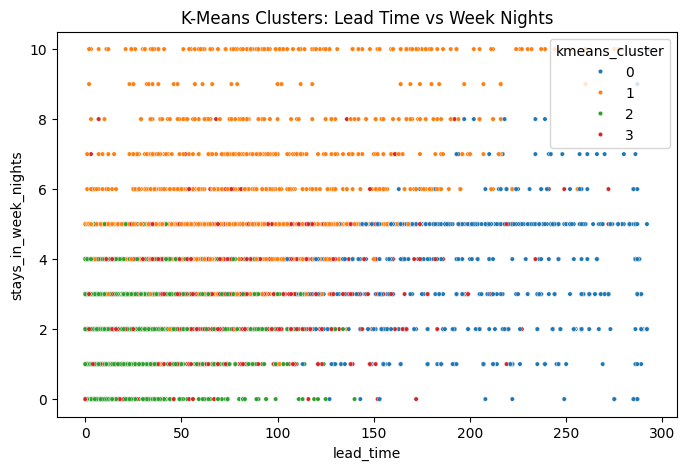

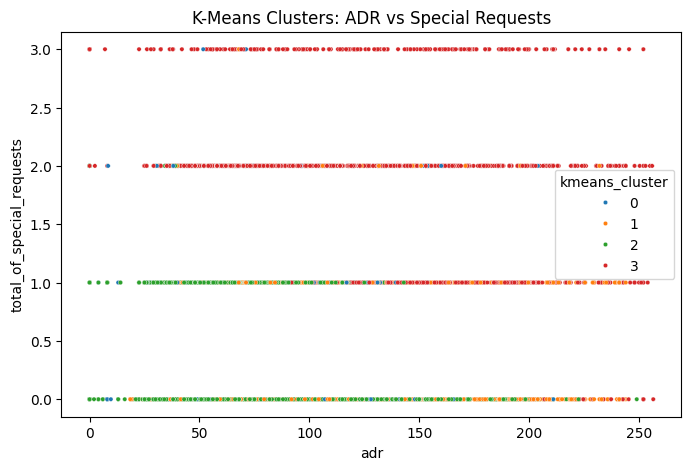

,lead_time,stays_in_weekend_nights,stays_in_week_nights,adr,total_of_special_requests,guests
kmeans_cluster,,,,,,
0,211.01,1.27,3.47,70.11,0.37,777
1,79.96,2.31,5.61,109.56,0.46,1925
2,16.70,0.45,1.49,64.78,0.30,3206
3,55.46,1.02,2.89,126.84,1.80,1605


In [18]:
# compare k = 3, 4, and 5 before choosing
for k in [3, 4, 5]:
    model = KMeans(n_clusters=k, n_init=10, random_state=42)
    labels = model.fit_predict(X)
    print(f'k={k}  WCSS={model.inertia_:.1f}  Silhouette={silhouette_score(X, labels):.3f}')

# fit the final model with k = 4 and assign a cluster to each guest
kmeans = KMeans(n_clusters=4, n_init=10, random_state=42)
hotels['kmeans_cluster'] = kmeans.fit_predict(X)

# scatterplot 1: lead time vs week nights
plt.figure(figsize=(8, 5))
sns.scatterplot(data=hotels, x='lead_time', y='stays_in_week_nights', hue='kmeans_cluster', palette='tab10', s=10)
plt.title('K-Means Clusters: Lead Time vs Week Nights')
plt.show()

# scatterplot 2: average daily rate vs special requests
plt.figure(figsize=(8, 5))
sns.scatterplot(data=hotels, x='adr', y='total_of_special_requests', hue='kmeans_cluster', palette='tab10', s=10)
plt.title('K-Means Clusters: ADR vs Special Requests')
plt.show()

# average of each feature by cluster, plus cluster size
kmeans_summary = hotels.groupby('kmeans_cluster')[features].mean().round(2)
kmeans_summary['guests'] = hotels['kmeans_cluster'].value_counts()
display(kmeans_summary)

### Reflection:
1. What `k` value did you choose, and how did you decide?

2. For each cluster answer the following - what types of customers seem to show up in the cluster?  which variables are most prominent or important for that cluster?  

### ✍️ Your Response: 🔧
1. I chose k = 4. Of k = 3, 4, and 5, k = 4 had the highest silhouette score at 0.290, against 0.280 and 0.283. WCSS fell at every step, from 21931.5 to 16491.9, so it did not point to one k. Four groups is also a workable number of email campaigns.

2. Cluster 0 (777 guests): Early planners. Lead_time is the key variable at 211.01 days, far above every other cluster. In the Lead Time vs Week Nights chart, most points past about 200 days are cluster 0. Cluster 1 (1,925 guests): Long stays. Week nights (5.61) and weekend nights (2.31) are the highest of any cluster, and adr is 109.56. Most points at 6 to 10 week nights are cluster 1. Cluster 2 (3,206 guests): Last-minute short stays. It has the shortest lead_time (16.70), the fewest week nights (1.49) and weekend nights (0.45), and the lowest adr (64.78). It is the largest cluster. Cluster 3 (1,605 guests): High-paying guests with many requests. It has the highest adr (126.84) and the most special requests (1.80). In the ADR vs Special Requests chart, nearly all points at 2 and 3 requests are cluster 3.


## 4. Apply Gaussian Mixture Model (GMM)

### Business framing:  

Not all guests fit neatly into one cluster. GMM lets us capture uncertainty — useful if customers behave similarly across groups.

### Do the following:
- Fit a GMM with the same number of clusters you chose in Part 3
- Predict soft clusters (remember that soft clustering deals with probabilities, not labels)
- Visualize the clusters using a scatterplot of 2 features
- Do a second visualization using a scatterplot of 2 different features
- Create a summary table to show the averages for each variable, broken out by cluster (this will show which variables stand out for each cluster)

,prob_0,prob_1,prob_2,prob_3
0,0.0,0.0,1.0,0.0
1,0.0,0.0,1.0,0.0
2,1.0,0.0,0.0,0.0
3,0.0,0.0,1.0,0.0
4,1.0,0.0,0.0,0.0


Share of guests with no cluster above 0.90 probability: 0.0


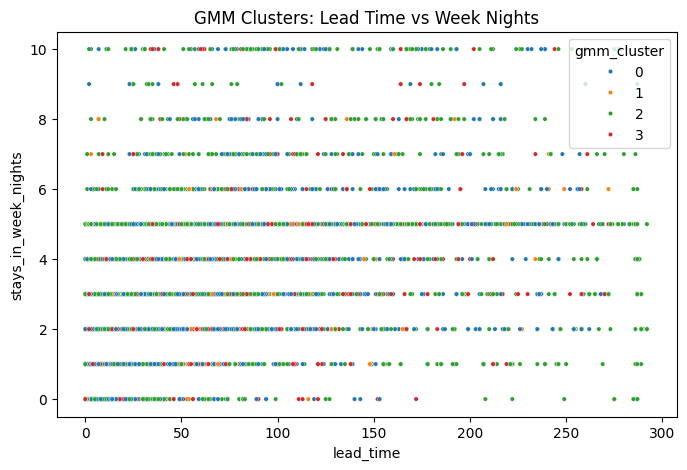

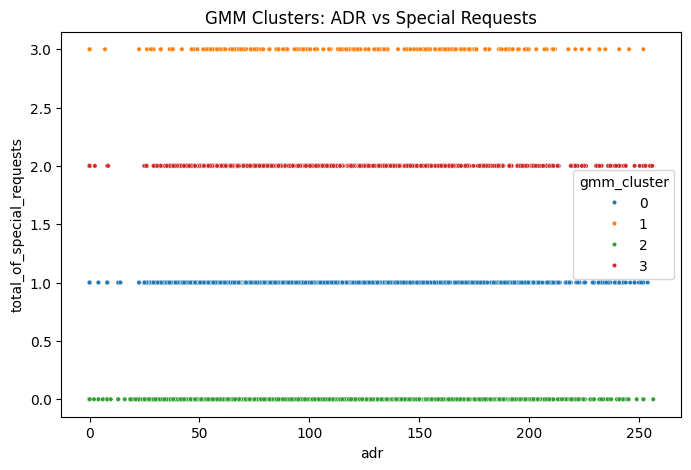

,lead_time,stays_in_weekend_nights,stays_in_week_nights,adr,total_of_special_requests,guests
gmm_cluster,,,,,,
0,62.13,1.23,3.20,95.41,1.0,2298
1,66.55,1.27,3.30,122.73,3.0,218
2,59.34,1.05,2.88,80.90,0.0,3963
3,65.74,1.20,3.27,106.37,2.0,1034


In [19]:
# fit a GMM with the same number of clusters (10 starts, same as K-Means)
gmm = GaussianMixture(n_components=4, n_init=10, random_state=42)
gmm.fit(X)

# soft clusters: the probability that each guest belongs to each cluster
probs = gmm.predict_proba(X)
display(pd.DataFrame(probs, columns=['prob_0', 'prob_1', 'prob_2', 'prob_3']).round(3).head())
print('Share of guests with no cluster above 0.90 probability:', round((probs.max(axis=1) < 0.90).mean(), 3))

# label each guest with their most likely cluster for the charts
hotels['gmm_cluster'] = gmm.predict(X)

# scatterplot 1: lead time vs week nights
plt.figure(figsize=(8, 5))
sns.scatterplot(data=hotels, x='lead_time', y='stays_in_week_nights', hue='gmm_cluster', palette='tab10', s=10)
plt.title('GMM Clusters: Lead Time vs Week Nights')
plt.show()

# scatterplot 2: average daily rate vs special requests
plt.figure(figsize=(8, 5))
sns.scatterplot(data=hotels, x='adr', y='total_of_special_requests', hue='gmm_cluster', palette='tab10', s=10)
plt.title('GMM Clusters: ADR vs Special Requests')
plt.show()

# average of each feature by cluster, plus cluster size
gmm_summary = hotels.groupby('gmm_cluster')[features].mean().round(2)
gmm_summary['guests'] = hotels['gmm_cluster'].value_counts()
display(gmm_summary)

### Reflection:
1. How did the GMM results compare to KMeans?
2. What business questions might GMM help answer better?

### ✍️ Your Response: 🔧
1. The GMM clusters line up with special requests. Its four clusters average 0.0, 1.0, 2.0, and 3.0 requests, and the ADR vs Special Requests chart shows one color per request row. The other averages sit close together, with lead_time between 59.34 and 66.55 days. The soft probabilities in the preview round to 0.0 or 1.0, and the share of guests with no cluster above 0.90 is 0.0. K-Means split guests on lead time, stay length, adr, and special requests.

2. GMM could help answer questions such as: Which guests sit between two segments? How sure are we that a guest belongs to the early-planner group? A guest who is partly an early planner and partly a long-stay guest could get both offers. On this data GMM gave every guest one clear cluster, so it did not answer those questions here.


## 5. Evaluate Your Models

### Business framing:  

In business, models should be both useful and reliable. You’ll compare model quality using standard evaluation metrics.

### Do the following:
- 5.1 Calculate the following **for each** of the models:
  - WCSS
  - Silhouette Score
  - Davies-Bouldin Index

  **NOTE:** This step may take up to 5 minutes.  It is a lot of computation time.  Please be patient.  Or you can limit the scores to using a random sample of 10K rows.

**Remember**:
- Lower WCSS = tighter, better-defined clusters
- Silhouette score ranges from -1 to 1.  Higher values = better clustering
- Lower Davies-Boulding Index = better clustering

In [20]:
# WCSS: total squared distance from each guest to the center of its cluster
def wcss(data, labels):
    total = 0
    for c in set(labels):
        points = data[labels == c]
        total += ((points - points.mean(axis=0)) ** 2).sum()
    return total

# the cleaned data has fewer than 10K rows, so all rows are used
kmeans_labels = hotels['kmeans_cluster'].values
gmm_labels = hotels['gmm_cluster'].values

scores = pd.DataFrame({
    'Model': ['K-Means', 'GMM'],
    'WCSS': [wcss(X, kmeans_labels), wcss(X, gmm_labels)],
    'Silhouette': [silhouette_score(X, kmeans_labels), silhouette_score(X, gmm_labels)],
    'Davies-Bouldin': [davies_bouldin_score(X, kmeans_labels), davies_bouldin_score(X, gmm_labels)]
}).round(3)
display(scores)

,Model,WCSS,Silhouette,Davies-Bouldin
0,K-Means,19002.942,0.290,1.352
1,GMM,29634.030,0.109,2.904


### Reflection:
5.2. Which model performed better on the metrics?

5.3. Would you recommend KMeans or GMM for a business analyst? Why?

### ✍️ Your Response: 🔧
5.2. K-Means performed better on all three metrics. It had a lower WCSS (19002.942 vs 29634.030), a higher silhouette score (0.290 vs 0.109), and a lower Davies-Bouldin Index (1.352 vs 2.904). Still, a silhouette of 0.290 is closer to 0 than to 1, so the K-Means clusters are only moderately separated. In the Lead Time vs Week Nights chart, clusters 1, 2, and 3 mix at lead times under about 150 days.

5.3. I would recommend K-Means. It scored better on all three metrics here, and its clusters differ on lead time, stay length, adr, and special requests, which a manager can act on. The GMM clusters lined up with request count alone, and its probabilities gave no extra information on this data. GMM is worth trying when guests clearly overlap between groups.

## 6. Business Interpretation

### Business framing:  

What do these clusters mean in the real world? Could they represent solo travelers, families, or bargain shoppers?

### Do the following:
- Display the characteristics of each cluster (e.g. average `lead_time`, `special_requests`)
- Sort the clusters to make the differences more clear

In [21]:
# profile each K-Means cluster: clustering features plus party size, cancellations, and repeat guests
profile_cols = features + ['adults', 'children', 'is_canceled', 'is_repeated_guest']
profile = hotels.groupby('kmeans_cluster')[profile_cols].mean().round(2)
profile['guests'] = hotels['kmeans_cluster'].value_counts()

# sort by lead time so the planners and last-minute bookers are easy to compare
display(profile.sort_values('lead_time', ascending=False))

,lead_time,stays_in_weekend_nights,stays_in_week_nights,adr,total_of_special_requests,adults,children,is_canceled,is_repeated_guest,guests
kmeans_cluster,,,,,,,,,,
0,211.01,1.27,3.47,70.11,0.37,1.85,0.04,0.26,0.03,777
1,79.96,2.31,5.61,109.56,0.46,1.96,0.15,0.22,0.01,1925
3,55.46,1.02,2.89,126.84,1.80,2.01,0.19,0.20,0.04,1605
2,16.70,0.45,1.49,64.78,0.30,1.64,0.07,0.11,0.16,3206


### Reflection:
1. What do the segments represent in terms of guest behavior?
2. How could the hotel tailor services or promotions to each group?

### ✍️ Your Response: 🔧
1. In lead_time order, the segments are early planners (cluster 0), long stays (cluster 1), high-paying guests with many requests (cluster 3), and last-minute short stays (cluster 2).

2. Cluster 0 books 211.01 days ahead on average and has the highest share of canceled bookings (0.26). The hotel could offer early-booking rates and send reminders before arrival. Cluster 1 stays the longest, with 5.61 week nights and 2.31 weekend nights. The hotel could offer weekly rates or stay-longer discounts. Cluster 3 has the highest adr (126.84) and makes the most special requests (1.80). It also has the most children per booking (0.19). The hotel could offer upgrades and a pre-arrival request form. Cluster 2 is the largest group (3,206 bookings), with the highest repeat-guest share (0.16) and the lowest share of canceled bookings (0.11). The hotel could send last-minute deals and loyalty rewards.


## 7. Final Reflection

### Business framing:  

Many teams ask for "segmentation" without knowing how it works. You now have hands-on experience with two clustering techniques and how to present the results.

### Reflection:
1. What was most challenging about unsupervised learning?
2. When would you use clustering instead of supervised models?
3. How would you explain the value of clustering to a non-technical manager?
4. How does this relate to your customized learning outcome you created in canvas?


### ✍️ Your Response: 🔧
1. The hardest part was that unsupervised learning has no right answer to check against. I had to judge the clusters from metrics, charts, and averages. The GMM looked like four segments until the summary table showed its clusters lined up with request count alone.

2. I would use clustering when there is no label to predict. A supervised model needs a target such as is_canceled. Clustering finds groups when I do not know the groups ahead of time.

3. For a non-technical manager, I would say clustering sorts guests into groups that behave alike. Here it separated 3,206 last-minute short-stay bookings from 777 bookings made an average of 211.01 days ahead. Each group can get its own offer instead of one email for everyone.

4. My first outcome is: "I will be able to build a Python workflow that cleans and consistently categorizes messy client transaction data, so a diligence team can flag non-recurring items and quality-of-earnings adjustments without re-sorting by hand." This assignment used similar steps on hotel data. I removed duplicates, rows with a negative adr, and outliers, then grouped bookings by behavior. My second outcome is: "I will be able to evaluate AI-generated categorizations against the source financials by treating each output as a hypothesis to verify rather than an answer to trust, so I can frame which discrepancies actually matter before they reach a quality-of-earnings conclusion." The GMM output looked like four segments, but the summary table showed its clusters lined up with special requests alone. I treated the model output as a hypothesis, checked it against the data, and chose K-Means for the segments.

## Submission Instructions

✅ **Before submitting:**
- Make sure all code cells are run and outputs are visible  
- All markdown questions are answered thoughtfully  
- Submit the assignment as an **HTML file** on Canvas


In [24]:
!jupyter nbconvert --to html "assignment_09_clustering.ipynb"

[NbConvertApp] Converting notebook assignment_09_clustering.ipynb to html
[NbConvertApp] WARNING | Alternative text is missing on 4 image(s).
[NbConvertApp] Writing 757080 bytes to assignment_09_clustering.html
